# Land-Cover Classification of the Khumbu Icefall Region using Sentinel-2

**Task:** pixel-wise multi-class classification (Vegetation / Bare-Rock / Snow-Ice / Water) of the Khumbu Icefall â€“ Everest Base Camp area (Nepal) from Sentinel-2 L2A imagery.

| Item | Choice |
|---|---|
| Imagery | Sentinel-2 L2A (Microsoft Planetary Computer STAC, no API key needed) |
| Ground truth | ESA WorldCover 2021 v200 (10 m), same grid as Sentinel-2 |
| Model 1 | **MLP** (neural network) on per-pixel spectral features |
| Model 2 | **CNN** (deep learning) on 9Ã—9 spatial patches |
| Metrics | Precision, Recall, F1, AUC-ROC (one-vs-rest), confusion matrix |

**Data links**
- Sentinel-2 L2A: https://planetarycomputer.microsoft.com/dataset/sentinel-2-l2a
- ESA WorldCover: https://planetarycomputer.microsoft.com/dataset/esa-worldcover

**Run it in:** Google Colab (Runtime â†’ GPU recommended) or any local Jupyter with internet access.

> **Note on ground truth:** WorldCover is a published, validated land-cover product (not a field survey), derived from Sentinel-1/2 with its own training data. It is a standard reference for benchmarking, but its labels contain some noise (e.g., debris-covered ice in the icefall is often labelled as bare ground). Keep that in mind when interpreting the scores.

## 1. Setup

In [1]:
# Run this cell once (Colab / fresh environment). Safe to re-run.
# %pip install -q pystac-client planetary-computer stackstac rioxarray rasterio pyproj torch scikit-learn matplotlib pandas seaborn scipy

In [2]:
import os, time, warnings, json, math
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import seaborn as sns
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score,
                             roc_auc_score, roc_curve, auc, confusion_matrix,
                             classification_report)
from sklearn.preprocessing import label_binarize
from numpy.lib.stride_tricks import sliding_window_view
warnings.filterwarnings("ignore")

# ---------------- CONFIG ----------------
DATA_SOURCE = os.environ.get("DATA_SOURCE", "planetary_computer")  # "planetary_computer" | "local" | "synthetic"
QUICK_TEST  = os.environ.get("QUICK_TEST", "0") == "1"             # tiny run for smoke testing

# Khumbu Icefall / Everest Base Camp area  [lon_min, lat_min, lon_max, lat_max]
BBOX        = [86.84, 27.96, 86.96, 28.05]
ICEFALL_LONLAT = (86.899, 27.988)
DATE_RANGE  = "2021-10-01/2021-12-15"   # post-monsoon, clearest season; matches WorldCover 2021
MAX_CLOUD   = 20                        # % scene cloud cover
EPSG        = 32645                     # UTM 45N
RES         = 10                        # metres
BANDS       = ["B02", "B03", "B04", "B08", "B11", "B12"]   # Blue, Green, Red, NIR, SWIR1, SWIR2
CACHE_FILE  = "khumbu_s2_worldcover_cache.npz"

# local mode (your own GeoTIFFs)
LOCAL_IMAGE_TIF = "sentinel2_stack.tif"   # 6 bands in the order of BANDS
LOCAL_LABEL_TIF = "worldcover.tif"        # WorldCover codes on the same grid

SEED        = 42
PATCH       = 9                           # CNN patch size (odd)
BLOCK       = 64                          # spatial block size (px) for leak-free split
SPLIT_FRACS = (0.70, 0.15, 0.15)          # train / val / test blocks
CAP         = dict(train=20000, val=5000, test=10000)  # max samples per class per split
EPOCHS_MLP, EPOCHS_CNN = (3, 3) if QUICK_TEST else (40, 25)
if QUICK_TEST: CAP = dict(train=1500, val=500, test=800)

np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "| data source:", DATA_SOURCE)

Device: cuda | data source: planetary_computer


## 2. Load the data

Three options (set `DATA_SOURCE` above):
- `planetary_computer` â€“ downloads Sentinel-2 + WorldCover for the Khumbu bounding box, builds a cloud-masked **median composite** (Octâ€“Dec 2021), and caches it to disk.
- `local` â€“ use your own GeoTIFFs.
- `synthetic` â€“ generates fake data, **only for checking that the code runs**; never use it for results.

In [3]:
# WorldCover -> our 4 classes
WC_MAP = {10:0, 20:0, 30:0, 40:0, 90:0, 95:0, 100:0,   # vegetation (trees, shrub, grass, crop, wetland, mangrove, moss)
          50:1, 60:1,                                   # built-up + bare/sparse -> bare/rock
          70:2,                                         # snow & ice
          80:3}                                         # permanent water
ALL_CLASS_NAMES = ["Vegetation", "Bare/Rock", "Snow/Ice", "Water"]
ALL_COLORS      = ["#2e8b57", "#a0826d", "#e8f4ff", "#1f77b4"]

def remap_labels(wc):
    out = np.full(wc.shape, -1, dtype=np.int16)
    for k, v in WC_MAP.items(): out[wc == k] = v
    return out

def load_planetary_computer():
    import planetary_computer as pc, pystac_client, stackstac, pyproj
    from rasterio.enums import Resampling
    cat = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1",
                                    modifier=pc.sign_inplace)
    # bounds in UTM, snapped to the 10 m grid
    tr = pyproj.Transformer.from_crs(4326, EPSG, always_xy=True)
    xs, ys = zip(*[tr.transform(x, y) for x in (BBOX[0], BBOX[2]) for y in (BBOX[1], BBOX[3])])
    bounds = (math.floor(min(xs)/RES)*RES, math.floor(min(ys)/RES)*RES,
              math.ceil(max(xs)/RES)*RES,  math.ceil(max(ys)/RES)*RES)

    items = cat.search(collections=["sentinel-2-l2a"], bbox=BBOX, datetime=DATE_RANGE,
                       query={"eo:cloud_cover": {"lt": MAX_CLOUD}}).item_collection()
    print(f"Sentinel-2 scenes found: {len(items)}")
    if len(items) == 0: raise RuntimeError("No scenes found - widen DATE_RANGE or raise MAX_CLOUD.")

    spec = stackstac.stack(items, assets=BANDS, epsg=EPSG, resolution=RES, bounds=bounds,
                           resampling=Resampling.bilinear, dtype="float64",
                           fill_value=np.nan, chunksize=1024)
    scl  = stackstac.stack(items, assets=["SCL"], epsg=EPSG, resolution=RES, bounds=bounds,
                           resampling=Resampling.nearest, dtype="float64",
                           rescale=False, fill_value=np.nan, chunksize=1024).sel(band="SCL")
    bad  = scl.isin([0, 1, 3, 8, 9, 10])            # no-data, saturated, cloud shadow, clouds, cirrus
    comp = spec.where(~bad).median("time", skipna=True).compute()   # (band, y, x) reflectance
    img  = np.clip(comp.sel(band=BANDS).values, 0, 1).astype("float32")
    print("Composite:", img.shape)

    wc_items = cat.search(collections=["esa-worldcover"], bbox=BBOX,
                          datetime="2021-01-01/2021-12-31").item_collection()
    if len(wc_items) == 0:
        wc_items = cat.search(collections=["esa-worldcover"], bbox=BBOX).item_collection()
    wc = stackstac.stack(wc_items, assets=["map"], epsg=EPSG, resolution=RES, bounds=bounds,
                         resampling=Resampling.nearest, dtype="float64", rescale=False, fill_value=np.nan)
    wc = wc.max("time", skipna=True).squeeze().compute().values
    labels = remap_labels(np.nan_to_num(wc, nan=0).astype(int))
    meta = dict(bounds=bounds, epsg=EPSG)
    return img, labels, meta

def load_local():
    import rasterio
    with rasterio.open(LOCAL_IMAGE_TIF) as f:
        img = f.read().astype("float32"); b = f.bounds
        meta = dict(bounds=(b.left, b.bottom, b.right, b.top), epsg=f.crs.to_epsg())
    if np.nanmax(img) > 2: img = img / 10000.0
    with rasterio.open(LOCAL_LABEL_TIF) as f: wc = f.read(1)
    return np.clip(img, 0, 1), remap_labels(wc), meta

def make_synthetic(H=256, W=256):
    from scipy.ndimage import gaussian_filter
    rng = np.random.default_rng(SEED)
    f = gaussian_filter(rng.normal(size=(H, W)), 18); f = (f - f.min()) / (f.max() - f.min())
    lab = np.digitize(f, np.quantile(f, [0.25, 0.60, 0.95])).astype(np.int16)  # 0..3
    mean = np.array([[.03,.06,.04,.35,.20,.10], [.12,.15,.18,.22,.30,.28],
                     [.80,.82,.80,.78,.15,.10], [.05,.04,.03,.02,.01,.01]], dtype="float32")
    img = mean[lab].transpose(2,0,1) + rng.normal(0, .05, (6,H,W)) \
          + gaussian_filter(rng.normal(0, .05, (6,H,W)), (0,3,3))*3
    return np.clip(img, 0, 1).astype("float32"), lab, dict(bounds=None, epsg=None)

t0 = time.time()
if DATA_SOURCE == "synthetic":
    img, labels, meta = make_synthetic()
elif DATA_SOURCE == "local":
    img, labels, meta = load_local()
elif os.path.exists(CACHE_FILE):
    z = np.load(CACHE_FILE, allow_pickle=True); img, labels, meta = z["img"], z["labels"], z["meta"].item()
    print("Loaded from cache:", CACHE_FILE)
else:
    img, labels, meta = load_planetary_computer()
    np.savez_compressed(CACHE_FILE, img=img, labels=labels, meta=np.array(meta, dtype=object))
print(f"img {img.shape}, labels {labels.shape}, loaded in {time.time()-t0:.0f}s")

Sentinel-2 scenes found: 6
Composite: (6, 999, 1181)
img (6, 999, 1181), labels (999, 1181), loaded in 31s


## 3. Exploratory data analysis

Scene: 999 x 1181 px = 1,179,819 pixels | valid: 1,074,546 (91.1%)
Classes used: {'Vegetation': np.int64(558), 'Bare/Rock': np.int64(96063), 'Snow/Ice': np.int64(977384), 'Water': np.int64(541)}


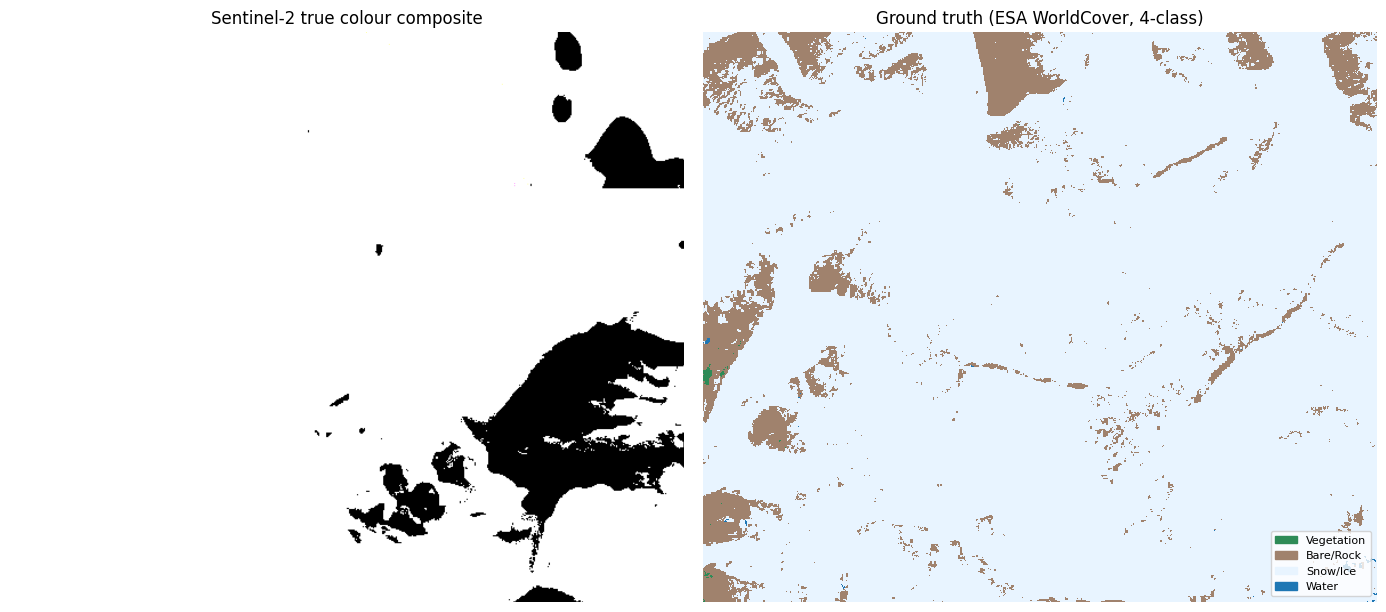

In [4]:
C, H, W = img.shape
valid = np.isfinite(img).all(0) & (labels >= 0)
print(f"Scene: {H} x {W} px = {H*W:,} pixels | valid: {valid.sum():,} ({valid.mean():.1%})")

# Classes actually present (rare/absent ones are dropped and ids made contiguous)
counts_raw = np.bincount(labels[valid], minlength=4)
present = [k for k in range(4) if counts_raw[k] >= 500]
remap = {old: new for new, old in enumerate(present)}
lab = np.full_like(labels, -1)
for old, new in remap.items(): lab[labels == old] = new
CLASS_NAMES = [ALL_CLASS_NAMES[k] for k in present]
COLORS      = [ALL_COLORS[k] for k in present]
NC = len(present)
valid = np.isfinite(img).all(0) & (lab >= 0)
img = np.nan_to_num(img, nan=0.0)
print("Classes used:", dict(zip(CLASS_NAMES, np.bincount(lab[valid]))))

cmap = ListedColormap(COLORS)
def rgb(im, gain=3.0):
    return np.clip(im[[2,1,0]].transpose(1,2,0) * gain, 0, 1)
def show_label(ax, l, title):
    ax.imshow(np.where(l >= 0, l, np.nan), cmap=cmap, vmin=0, vmax=NC-1, interpolation="nearest")
    ax.set_title(title); ax.axis("off")

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].imshow(rgb(img)); ax[0].set_title("Sentinel-2 true colour composite"); ax[0].axis("off")
show_label(ax[1], lab, "Ground truth (ESA WorldCover, 4-class)")
ax[1].legend(handles=[Patch(color=c, label=n) for c, n in zip(COLORS, CLASS_NAMES)],
             loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

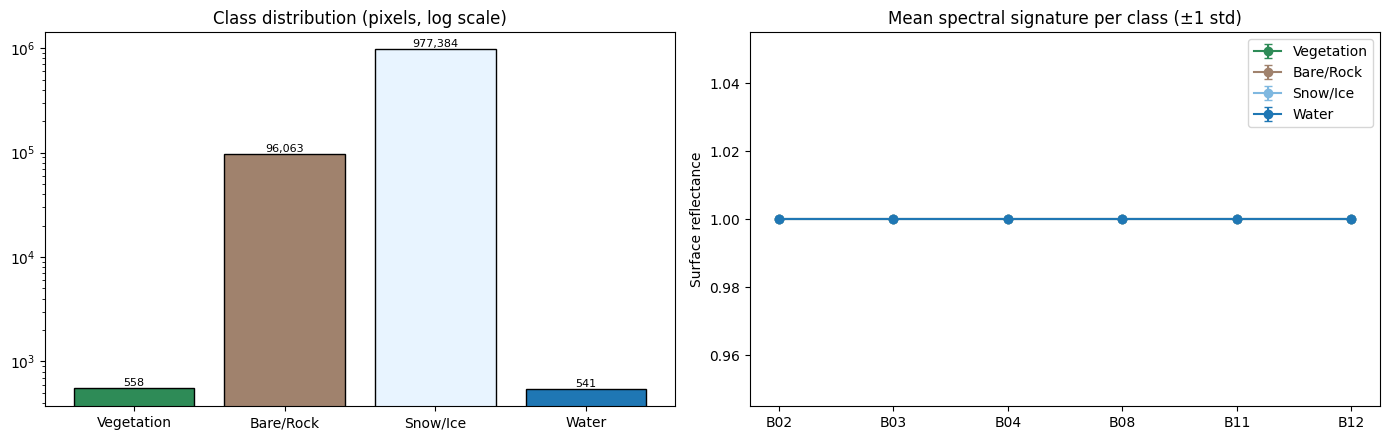

In [5]:
# Class distribution + spectral signatures
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
cnt = np.bincount(lab[valid], minlength=NC)
ax[0].bar(CLASS_NAMES, cnt, color=COLORS, edgecolor="k"); ax[0].set_yscale("log")
ax[0].set_title("Class distribution (pixels, log scale)")
for i, v in enumerate(cnt): ax[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)

rng = np.random.default_rng(SEED)
for k in range(NC):
    ys, xs = np.where((lab == k) & valid)
    sel = rng.choice(len(ys), min(5000, len(ys)), replace=False)
    px = img[:, ys[sel], xs[sel]]
    ax[1].errorbar(range(len(BANDS)), px.mean(1), px.std(1), label=CLASS_NAMES[k],
                   color=COLORS[k] if CLASS_NAMES[k] != "Snow/Ice" else "#7fb8e0", marker="o", capsize=3)
ax[1].set_xticks(range(len(BANDS))); ax[1].set_xticklabels(BANDS)
ax[1].set_ylabel("Surface reflectance"); ax[1].set_title("Mean spectral signature per class (Â±1 std)")
ax[1].legend(); plt.tight_layout(); plt.show()

## 4. Feature engineering

Six reflectance bands plus three spectral indices (**NDSI** snow, **NDVI** vegetation, **NDWI** water) â†’ 9 channels. NDSI is especially useful for separating snow/ice (high green, low SWIR) from bright rock.

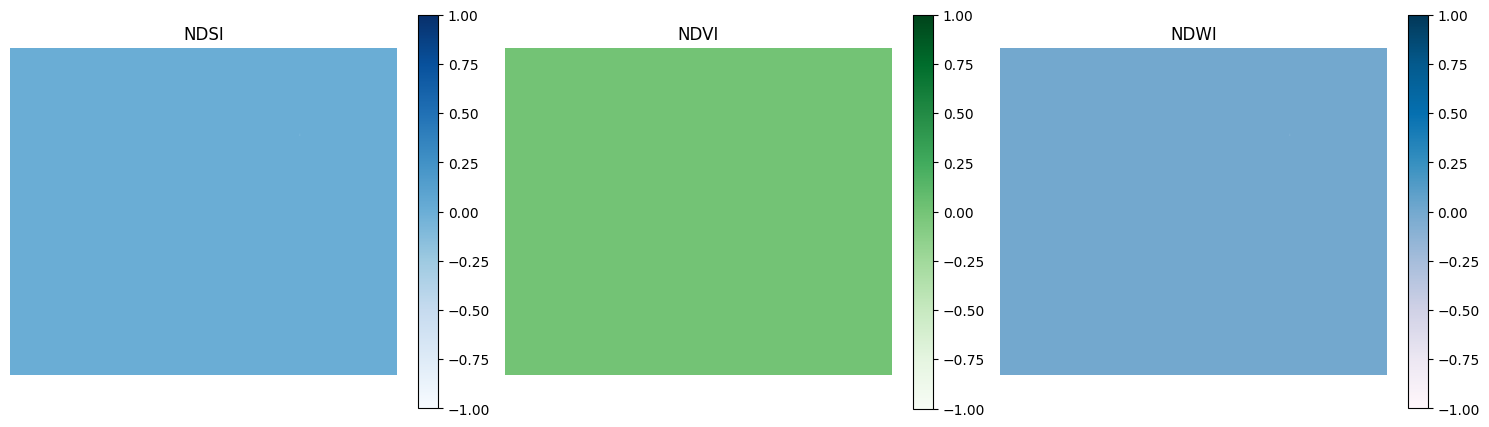

In [6]:
eps = 1e-6
B02, B03, B04, B08, B11, B12 = img
ndsi = (B03 - B11) / (B03 + B11 + eps)
ndvi = (B08 - B04) / (B08 + B04 + eps)
ndwi = (B03 - B08) / (B03 + B08 + eps)
FEATURES = BANDS + ["NDSI", "NDVI", "NDWI"]
X_img = np.concatenate([img, np.stack([ndsi, ndvi, ndwi])], 0).astype("float32")   # (9, H, W)
NF = X_img.shape[0]

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for a, (n, m, c) in zip(ax, [("NDSI", ndsi, "Blues"), ("NDVI", ndvi, "Greens"), ("NDWI", ndwi, "PuBu")]):
    im = a.imshow(m, cmap=c, vmin=-1, vmax=1); a.set_title(n); a.axis("off"); plt.colorbar(im, ax=a, fraction=.046)
plt.tight_layout(); plt.show()

## 5. Train / validation / test split

Neighbouring pixels are highly correlated, so a random pixel split would leak information (especially for the CNN, whose patches overlap). Instead the scene is cut into **64Ã—64 px spatial blocks** and whole blocks are assigned to train (70 %), validation (15 %) or test (15 %). Pixels are then sampled per class with a cap, to limit class imbalance.

Channel statistics are computed on the **training pixels only**.

Split seed offset used: 49


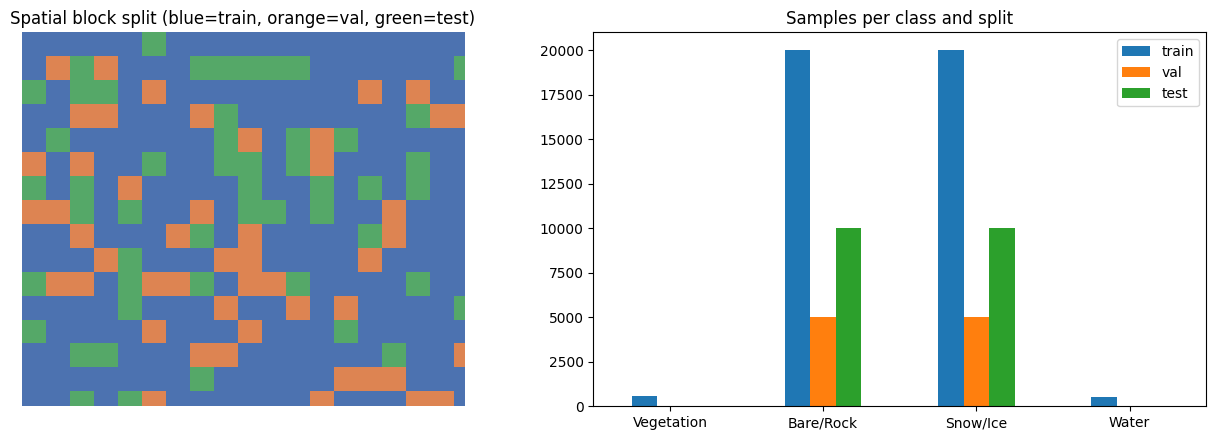

            train   val   test
Vegetation    550     2      6
Bare/Rock   20000  5000  10000
Snow/Ice    20000  5000  10000
Water         499     9     33


In [7]:
def block_split(H, W, block, fracs, seed):
    rng = np.random.default_rng(seed)
    nbh, nbw = math.ceil(H/block), math.ceil(W/block)
    ids = rng.choice(3, size=(nbh, nbw), p=fracs)
    return np.kron(ids, np.ones((block, block), dtype=int))[:H, :W]   # 0=train 1=val 2=test

split_map = block_split(H, W, BLOCK, SPLIT_FRACS, SEED)
# make sure every class occurs in each split's blocks, otherwise re-draw seed
for s in range(50):
    ok = all(((lab == k) & valid & (split_map == sp)).sum() > 50 for k in range(NC) for sp in range(3))
    if ok: break
    split_map = block_split(H, W, BLOCK, SPLIT_FRACS, SEED + s + 1)
print("Split seed offset used:", s)

def sample_idx(sp, cap, seed):
    rng = np.random.default_rng(seed + sp)
    rows, cols = [], []
    for k in range(NC):
        r, c = np.where((lab == k) & valid & (split_map == sp))
        sel = rng.permutation(len(r))[:cap]
        rows.append(r[sel]); cols.append(c[sel])
    r, c = np.concatenate(rows), np.concatenate(cols)
    p = np.random.default_rng(seed).permutation(len(r))
    return r[p], c[p]

idx = {n: sample_idx(i, CAP[n], SEED) for i, n in enumerate(["train", "val", "test"])}

# normalisation from TRAIN pixels only
tr_r, tr_c = idx["train"]
mu  = X_img[:, tr_r, tr_c].mean(1)[:, None, None]
std = X_img[:, tr_r, tr_c].std(1)[:, None, None] + 1e-6
X_norm = ((X_img - mu) / std).astype("float32")
y = {n: lab[r, c].astype("int64") for n, (r, c) in idx.items()}

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].imshow(split_map, cmap=ListedColormap(["#4c72b0", "#dd8452", "#55a868"]), interpolation="nearest")
ax[0].set_title("Spatial block split (blue=train, orange=val, green=test)"); ax[0].axis("off")
df_cnt = pd.DataFrame({n: np.bincount(y[n], minlength=NC) for n in y}, index=CLASS_NAMES)
df_cnt.plot.bar(ax=ax[1]); ax[1].set_title("Samples per class and split"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()
print(df_cnt)

## 6. Build model inputs

- **MLP** input: the 9 features of the single pixel â†’ shape `(N, 9)`
- **CNN** input: a `9Ã—9` window centred on the pixel with all 9 channels â†’ shape `(N, 9, 9, 9)`

In [8]:
pad = PATCH // 2
X_pad = np.pad(X_norm, ((0, 0), (pad, pad), (pad, pad)), mode="reflect")
WIN = sliding_window_view(X_pad, (PATCH, PATCH), axis=(1, 2))        # (C, H, W, p, p) view, no copy

def get_patches(rows, cols):
    return np.ascontiguousarray(WIN[:, rows, cols].transpose(1, 0, 2, 3))   # (N, C, p, p)

Xp = {n: torch.from_numpy(get_patches(*idx[n])) for n in idx}            # CNN
Xv = {n: torch.from_numpy(X_norm[:, idx[n][0], idx[n][1]].T.copy()) for n in idx}   # MLP
Yt = {n: torch.from_numpy(y[n]) for n in y}
print("MLP input :", Xv["train"].shape, "| CNN input:", Xp["train"].shape)

MLP input : torch.Size([41049, 9]) | CNN input: torch.Size([41049, 9, 9, 9])


## 7. Models

### 7.1 MLP (neural network, pixel-wise)
Three hidden layers (128-64-32) with BatchNorm, ReLU and Dropout. It sees only spectral information of a single pixel.

### 7.2 CNN (deep learning, patch-based)
Three conv blocks (32-64-128 filters, 3Ã—3, BatchNorm + ReLU), global average pooling and a dense classifier. It also learns **spatial context** (texture, neighbouring pixels), which should help in areas like the crevassed, debris-covered icefall.

In [9]:
class MLP(nn.Module):
    def __init__(self, n_in, n_cls):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_in, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(128, 64),   nn.BatchNorm1d(64),  nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(64, 32),    nn.BatchNorm1d(32),  nn.ReLU(),
            nn.Linear(32, n_cls))
    def forward(self, x): return self.net(x)

class CNN(nn.Module):
    def __init__(self, n_ch, n_cls):
        super().__init__()
        def block(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU())
        self.features = nn.Sequential(block(n_ch, 32), block(32, 64), nn.MaxPool2d(2), block(64, 128),
                                      nn.AdaptiveAvgPool2d(1), nn.Flatten())
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, n_cls))
    def forward(self, x): return self.head(self.features(x))

mlp, cnn = MLP(NF, NC).to(DEVICE), CNN(NF, NC).to(DEVICE)
nparams = lambda m: sum(p.numel() for p in m.parameters())
print(f"MLP parameters: {nparams(mlp):,} | CNN parameters: {nparams(cnn):,}")

MLP parameters: 12,196 | CNN parameters: 103,940


## 8. Training

Adam optimiser, class-weighted cross-entropy, ReduceLROnPlateau scheduler, and early stopping on **validation macro-F1** (best weights are restored).

In [10]:
@torch.no_grad()
def predict_proba(model, X, bs=4096):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        out.append(torch.softmax(model(X[i:i+bs].to(DEVICE)), 1).cpu())
    return torch.cat(out).numpy()

def train_model(model, name, Xtr, ytr, Xva, yva, epochs, bs, lr=1e-3, patience=8):
    cw = torch.tensor(len(ytr) / (NC * np.bincount(ytr.numpy(), minlength=NC)), dtype=torch.float32).to(DEVICE)
    crit = nn.CrossEntropyLoss(weight=cw)
    opt  = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=3)
    dl = DataLoader(TensorDataset(Xtr, ytr), batch_size=bs, shuffle=True)
    hist = dict(train_loss=[], val_loss=[], val_f1=[], val_acc=[])
    best_f1, best_state, wait = -1, None, 0
    for ep in range(epochs):
        model.train(); tl = 0
        for xb, yb in dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad(); loss = crit(model(xb), yb); loss.backward(); opt.step()
            tl += loss.item() * len(xb)
        pv = predict_proba(model, Xva)
        vl = nn.functional.nll_loss(torch.log(torch.tensor(pv) + 1e-9), yva).item()
        vf = f1_score(yva, pv.argmax(1), average="macro"); va = accuracy_score(yva, pv.argmax(1))
        sched.step(vl)
        hist["train_loss"].append(tl / len(Xtr)); hist["val_loss"].append(vl)
        hist["val_f1"].append(vf); hist["val_acc"].append(va)
        print(f"[{name}] epoch {ep+1:02d}/{epochs} train_loss {tl/len(Xtr):.4f} | val_loss {vl:.4f} "
              f"| val_acc {va:.4f} | val_macroF1 {vf:.4f}")
        if vf > best_f1:
            best_f1, wait = vf, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience: print("Early stopping."); break
    model.load_state_dict(best_state)
    return hist

t0 = time.time()
hist_mlp = train_model(mlp, "MLP", Xv["train"], Yt["train"], Xv["val"], Yt["val"], EPOCHS_MLP, bs=512)
print(f"MLP trained in {time.time()-t0:.0f}s")

[MLP] epoch 01/40 train_loss 1.4210 | val_loss 1.4287 | val_acc 0.0009 | val_macroF1 0.0004
[MLP] epoch 02/40 train_loss 1.3957 | val_loss 9.8758 | val_acc 0.4995 | val_macroF1 0.1665
[MLP] epoch 03/40 train_loss 1.3991 | val_loss 10.3496 | val_acc 0.4995 | val_macroF1 0.1665
[MLP] epoch 04/40 train_loss 1.3914 | val_loss 5.3953 | val_acc 0.4995 | val_macroF1 0.1665
[MLP] epoch 05/40 train_loss 1.3934 | val_loss 0.8751 | val_acc 0.4995 | val_macroF1 0.1665
[MLP] epoch 06/40 train_loss 1.3912 | val_loss 1.5577 | val_acc 0.4995 | val_macroF1 0.1665
[MLP] epoch 07/40 train_loss 1.3889 | val_loss 3.1690 | val_acc 0.4995 | val_macroF1 0.1665
[MLP] epoch 08/40 train_loss 1.3888 | val_loss 2.9182 | val_acc 0.0009 | val_macroF1 0.0004
[MLP] epoch 09/40 train_loss 1.3897 | val_loss 3.2364 | val_acc 0.0009 | val_macroF1 0.0004
[MLP] epoch 10/40 train_loss 1.3895 | val_loss 1.5724 | val_acc 0.4995 | val_macroF1 0.1665
Early stopping.
MLP trained in 10s


[CNN] epoch 01/25 train_loss 1.3805 | val_loss 1.3445 | val_acc 0.4967 | val_macroF1 0.1767
[CNN] epoch 02/25 train_loss 1.3825 | val_loss 1.3506 | val_acc 0.4980 | val_macroF1 0.1767
[CNN] epoch 03/25 train_loss 1.3782 | val_loss 1.3451 | val_acc 0.5035 | val_macroF1 0.1763
[CNN] epoch 04/25 train_loss 1.3776 | val_loss 1.3435 | val_acc 0.5048 | val_macroF1 0.1748
[CNN] epoch 05/25 train_loss 1.3771 | val_loss 1.3398 | val_acc 0.4992 | val_macroF1 0.1748
[CNN] epoch 06/25 train_loss 1.3768 | val_loss 1.3387 | val_acc 0.5000 | val_macroF1 0.1756
[CNN] epoch 07/25 train_loss 1.3768 | val_loss 1.3546 | val_acc 0.4983 | val_macroF1 0.1763
[CNN] epoch 08/25 train_loss 1.3790 | val_loss 1.3478 | val_acc 0.4977 | val_macroF1 0.1765
[CNN] epoch 09/25 train_loss 1.3769 | val_loss 1.3479 | val_acc 0.4990 | val_macroF1 0.1753
[CNN] epoch 10/25 train_loss 1.3772 | val_loss 1.3496 | val_acc 0.4977 | val_macroF1 0.1732
Early stopping.
CNN trained in 17s


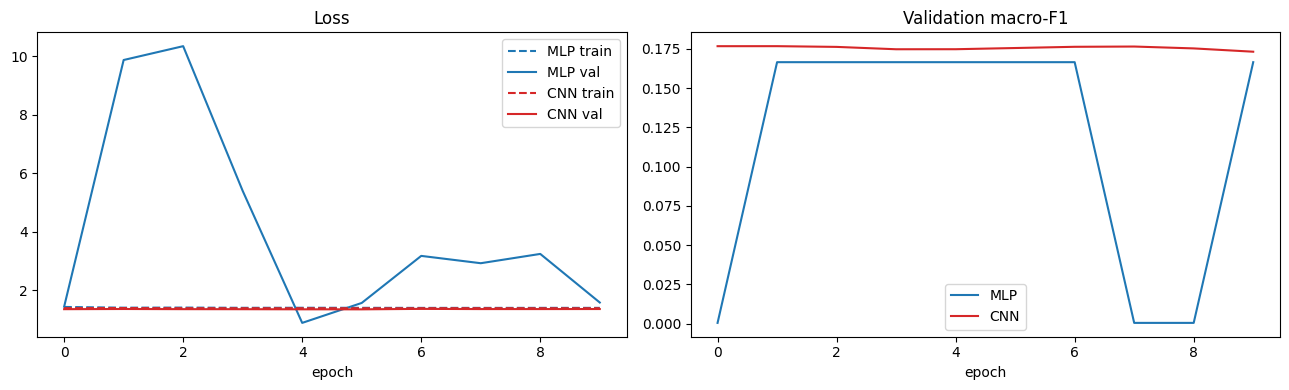

In [11]:
t0 = time.time()
hist_cnn = train_model(cnn, "CNN", Xp["train"], Yt["train"], Xp["val"], Yt["val"], EPOCHS_CNN, bs=256)
print(f"CNN trained in {time.time()-t0:.0f}s")
torch.save(mlp.state_dict(), "mlp_khumbu.pt"); torch.save(cnn.state_dict(), "cnn_khumbu.pt")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for h, n, c in [(hist_mlp, "MLP", "tab:blue"), (hist_cnn, "CNN", "tab:red")]:
    ax[0].plot(h["train_loss"], "--", color=c, label=f"{n} train"); ax[0].plot(h["val_loss"], color=c, label=f"{n} val")
    ax[1].plot(h["val_f1"], color=c, label=n)
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].set_title("Validation macro-F1"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

## 9. Evaluation on the held-out test blocks

Metrics: **precision, recall, F1** (macro-averaged and per class) and **AUC-ROC** (one-vs-rest). Test blocks were never seen during training or model selection.

In [12]:
probs = {"MLP": predict_proba(mlp, Xv["test"]), "CNN": predict_proba(cnn, Xp["test"])}
y_test = y["test"]

def metrics_row(p):
    pred = p.argmax(1)
    auc_ovr = roc_auc_score(y_test, p[:, 1]) if NC == 2 else roc_auc_score(y_test, p, multi_class="ovr", average="macro")
    return dict(Accuracy=accuracy_score(y_test, pred),
                Precision=precision_score(y_test, pred, average="macro", zero_division=0),
                Recall=recall_score(y_test, pred, average="macro", zero_division=0),
                F1=f1_score(y_test, pred, average="macro", zero_division=0),
                AUC_ROC=auc_ovr)

results = pd.DataFrame({m: metrics_row(p) for m, p in probs.items()}).T.round(4)
results.columns = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)", "AUC-ROC (macro OvR)"]
results.to_csv("results_summary.csv")
display(results)

for m, p in probs.items():
    print(f"\n===== {m}: per-class report =====")
    print(classification_report(y_test, p.argmax(1), target_names=CLASS_NAMES, digits=4, zero_division=0))

,Accuracy,Precision (macro),Recall (macro),F1 (macro),AUC-ROC (macro OvR)
MLP,0.4990,0.1248,0.2500,0.1665,0.5000
CNN,0.4988,0.2473,0.2499,0.1719,0.5013



===== MLP: per-class report =====
              precision    recall  f1-score   support

  Vegetation     0.0000    0.0000    0.0000         6
   Bare/Rock     0.0000    0.0000    0.0000     10000
    Snow/Ice     0.4990    1.0000    0.6658     10000
       Water     0.0000    0.0000    0.0000        33

    accuracy                         0.4990     20039
   macro avg     0.1248    0.2500    0.1665     20039
weighted avg     0.2490    0.4990    0.3323     20039


===== CNN: per-class report =====
              precision    recall  f1-score   support

  Vegetation     0.0000    0.0000    0.0000         6
   Bare/Rock     0.4989    0.9869    0.6628     10000
    Snow/Ice     0.4903    0.0127    0.0248     10000
       Water     0.0000    0.0000    0.0000        33

    accuracy                         0.4988     20039
   macro avg     0.2473    0.2499    0.1719     20039
weighted avg     0.4937    0.4988    0.3431     20039



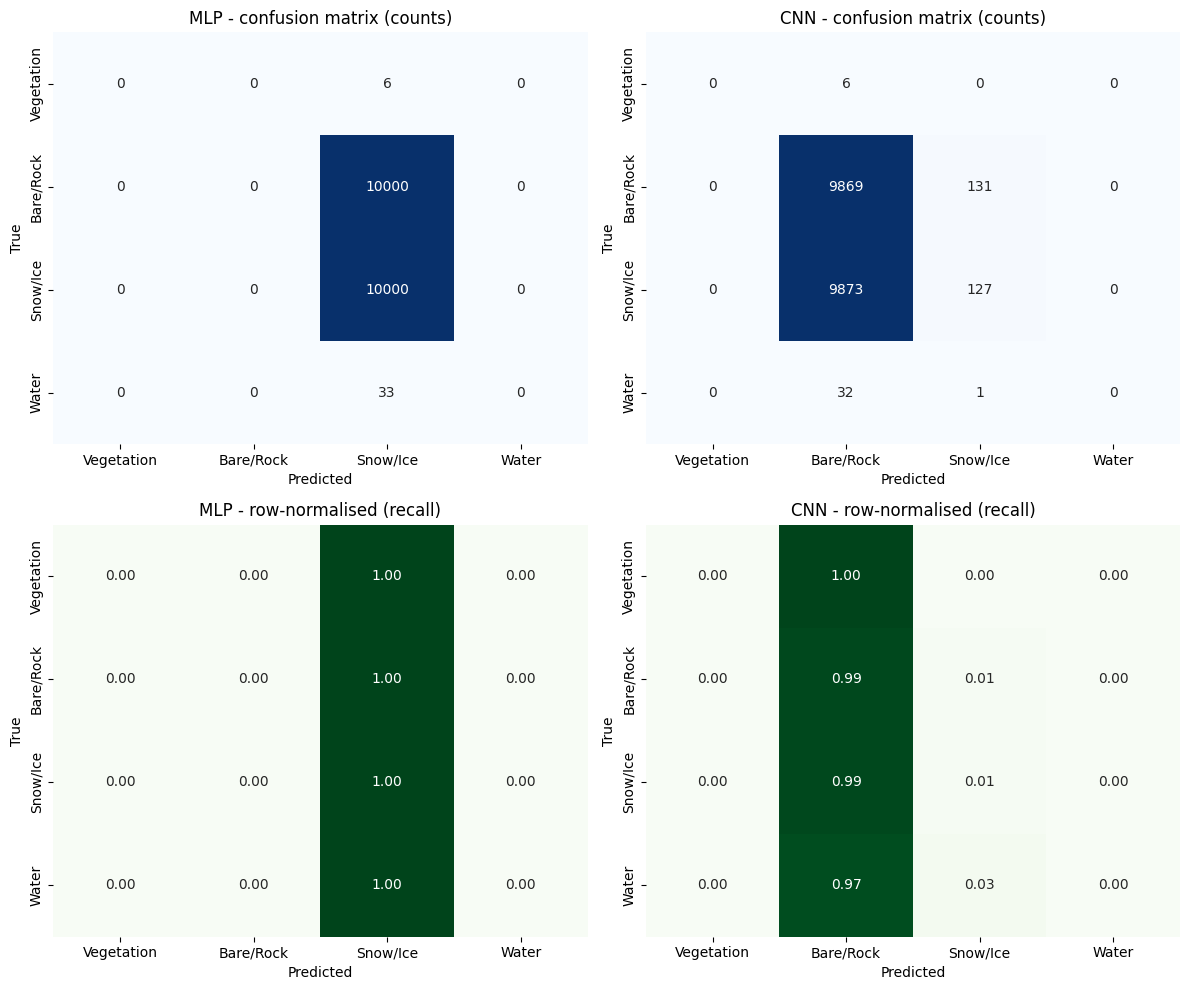

In [13]:
# Confusion matrices (counts + row-normalised)
fig, ax = plt.subplots(2, 2, figsize=(12, 10))
for j, (m, p) in enumerate(probs.items()):
    cm = confusion_matrix(y_test, p.argmax(1), labels=range(NC))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[0, j], cbar=False)
    ax[0, j].set_title(f"{m} - confusion matrix (counts)"); ax[0, j].set_xlabel("Predicted"); ax[0, j].set_ylabel("True")
    sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".2f", cmap="Greens", vmin=0, vmax=1,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[1, j], cbar=False)
    ax[1, j].set_title(f"{m} - row-normalised (recall)"); ax[1, j].set_xlabel("Predicted"); ax[1, j].set_ylabel("True")
plt.tight_layout(); plt.show()

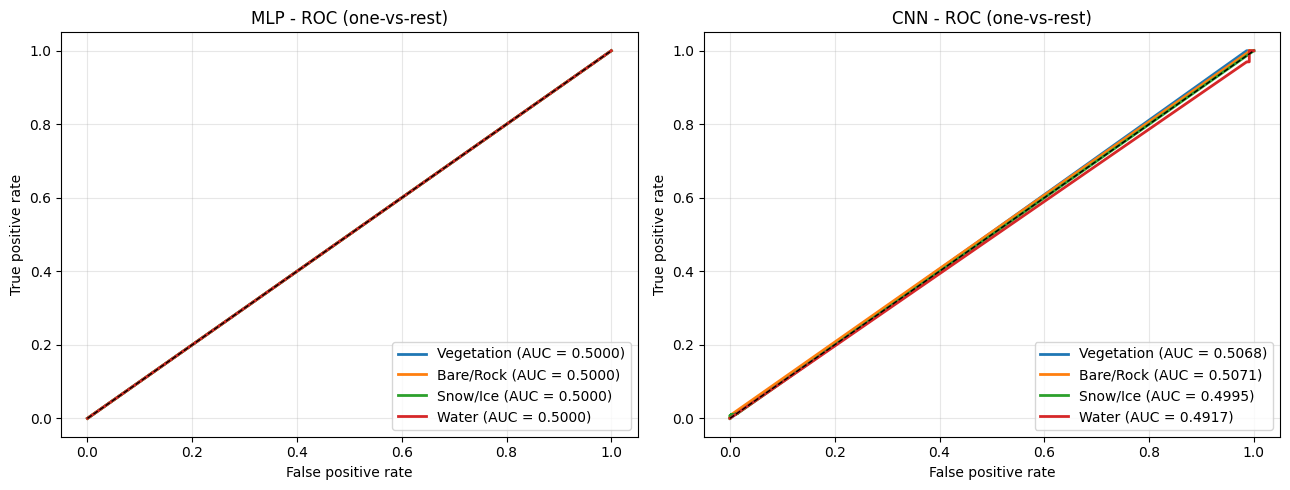

MLP                           CNN                        
           Precision Recall      F1  AUC Precision  Recall      F1     AUC
Vegetation     0.000    0.0  0.0000  0.5    0.0000  0.0000  0.0000  0.5068
Bare/Rock      0.000    0.0  0.0000  0.5    0.4989  0.9869  0.6628  0.5071
Snow/Ice       0.499    1.0  0.6658  0.5    0.4903  0.0127  0.0248  0.4995
Water          0.000    0.0  0.0000  0.5    0.0000  0.0000  0.0000  0.4917

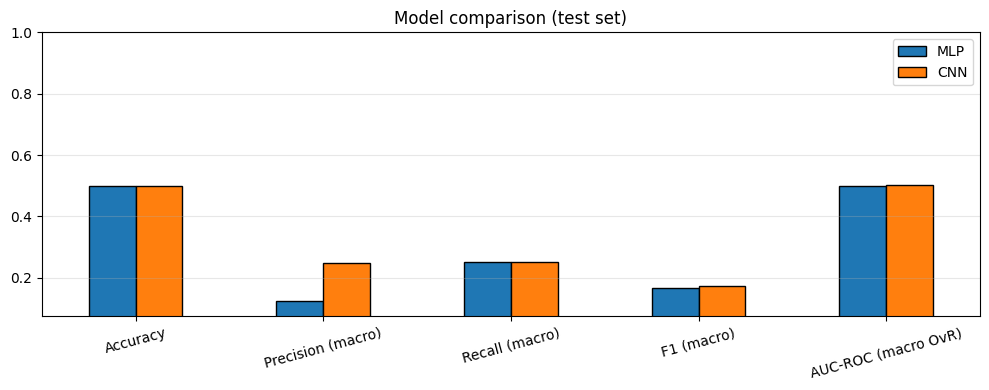

In [14]:
# ROC curves (one-vs-rest) per class, both models
Yb = label_binarize(y_test, classes=range(NC)) if NC > 2 else np.c_[1 - y_test, y_test]
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
auc_table = {}
for a, (m, p) in zip(ax, probs.items()):
    for k in range(NC):
        fpr, tpr, _ = roc_curve(Yb[:, k], p[:, k]); auc_k = auc(fpr, tpr)
        auc_table.setdefault(m, {})[CLASS_NAMES[k]] = auc_k
        a.plot(fpr, tpr, lw=2, label=f"{CLASS_NAMES[k]} (AUC = {auc_k:.4f})")
    a.plot([0, 1], [0, 1], "k--", lw=1)
    a.set_xlabel("False positive rate"); a.set_ylabel("True positive rate"); a.set_title(f"{m} - ROC (one-vs-rest)")
    a.legend(loc="lower right"); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

per_class = pd.concat({m: pd.DataFrame({
    "Precision": precision_score(y_test, p.argmax(1), average=None, zero_division=0),
    "Recall":    recall_score(y_test, p.argmax(1), average=None, zero_division=0),
    "F1":        f1_score(y_test, p.argmax(1), average=None, zero_division=0),
    "AUC":       [auc_table[m][c] for c in CLASS_NAMES]}, index=CLASS_NAMES) for m, p in probs.items()}, axis=1).round(4)
per_class.to_csv("results_per_class.csv"); display(per_class)

ax = results.iloc[:, :].T.plot.bar(figsize=(10, 4), rot=15, edgecolor="k")
ax.set_ylim(min(0.5, results.values.min() - .05), 1.0); ax.set_title("Model comparison (test set)"); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

## 10. Full-scene prediction maps

Both models are applied to every pixel of the scene and compared with the ground truth. The right-most panel shows where the CNN is wrong.

Scene prediction done in 8s


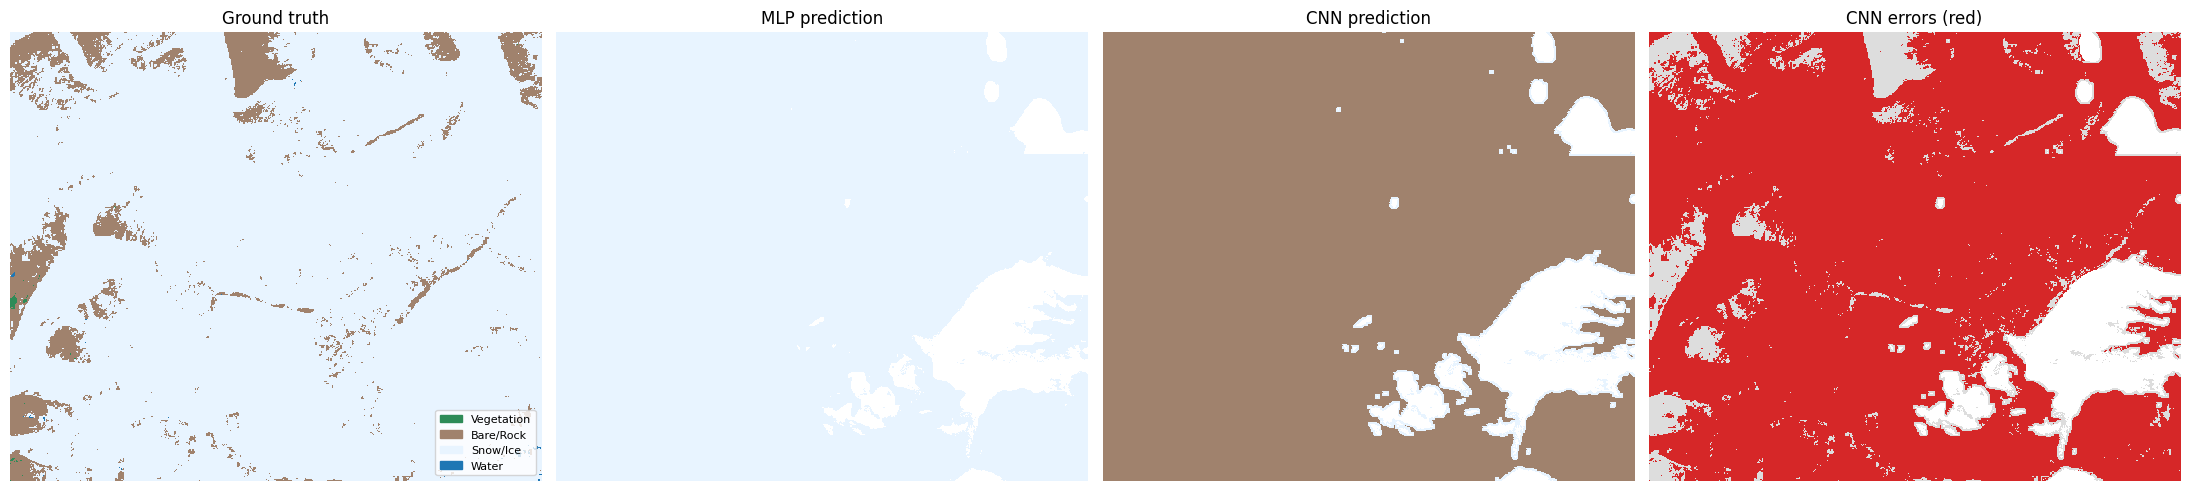

Whole-scene pixel accuracy (includes train blocks): MLP 0.9096 | CNN 0.1152
Test-block pixel accuracy (natural class distribution): MLP 0.9103 | CNN 0.0997


In [15]:
@torch.no_grad()
def predict_scene_mlp(model, bs=200_000):
    flat = torch.from_numpy(X_norm.reshape(NF, -1).T.copy()); out = []
    model.eval()
    for i in range(0, len(flat), bs): out.append(model(flat[i:i+bs].to(DEVICE)).argmax(1).cpu())
    return torch.cat(out).numpy().reshape(H, W)

@torch.no_grad()
def predict_scene_cnn(model, rows_per_chunk=8):
    model.eval(); out = np.zeros((H, W), dtype=np.int64)
    for r0 in range(0, H, rows_per_chunk):
        r1 = min(H, r0 + rows_per_chunk)
        chunk = np.ascontiguousarray(WIN[:, r0:r1].transpose(1, 2, 0, 3, 4).reshape(-1, NF, PATCH, PATCH))
        pred = model(torch.from_numpy(chunk).to(DEVICE)).argmax(1).cpu().numpy()
        out[r0:r1] = pred.reshape(r1 - r0, W)
    return out

t0 = time.time()
map_mlp = predict_scene_mlp(mlp); map_cnn = predict_scene_cnn(cnn)
print(f"Scene prediction done in {time.time()-t0:.0f}s")

err = np.where(valid, (map_cnn != lab).astype(float), np.nan)
fig, ax = plt.subplots(1, 4, figsize=(22, 6))
show_label(ax[0], lab, "Ground truth")
show_label(ax[1], np.where(valid, map_mlp, -1), "MLP prediction")
show_label(ax[2], np.where(valid, map_cnn, -1), "CNN prediction")
ax[3].imshow(err, cmap=ListedColormap(["#dddddd", "#d62728"]), vmin=0, vmax=1, interpolation="nearest")
ax[3].set_title("CNN errors (red)"); ax[3].axis("off")
ax[0].legend(handles=[Patch(color=c, label=n) for c, n in zip(COLORS, CLASS_NAMES)], loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

# note: full-scene accuracy includes training pixels - use test-set metrics above for honest numbers
print("Whole-scene pixel accuracy (includes train blocks):",
      f"MLP {np.mean(map_mlp[valid]==lab[valid]):.4f} | CNN {np.mean(map_cnn[valid]==lab[valid]):.4f}")
tm = valid & (split_map == 2)
print("Test-block pixel accuracy (natural class distribution):",
      f"MLP {np.mean(map_mlp[tm]==lab[tm]):.4f} | CNN {np.mean(map_cnn[tm]==lab[tm]):.4f}")

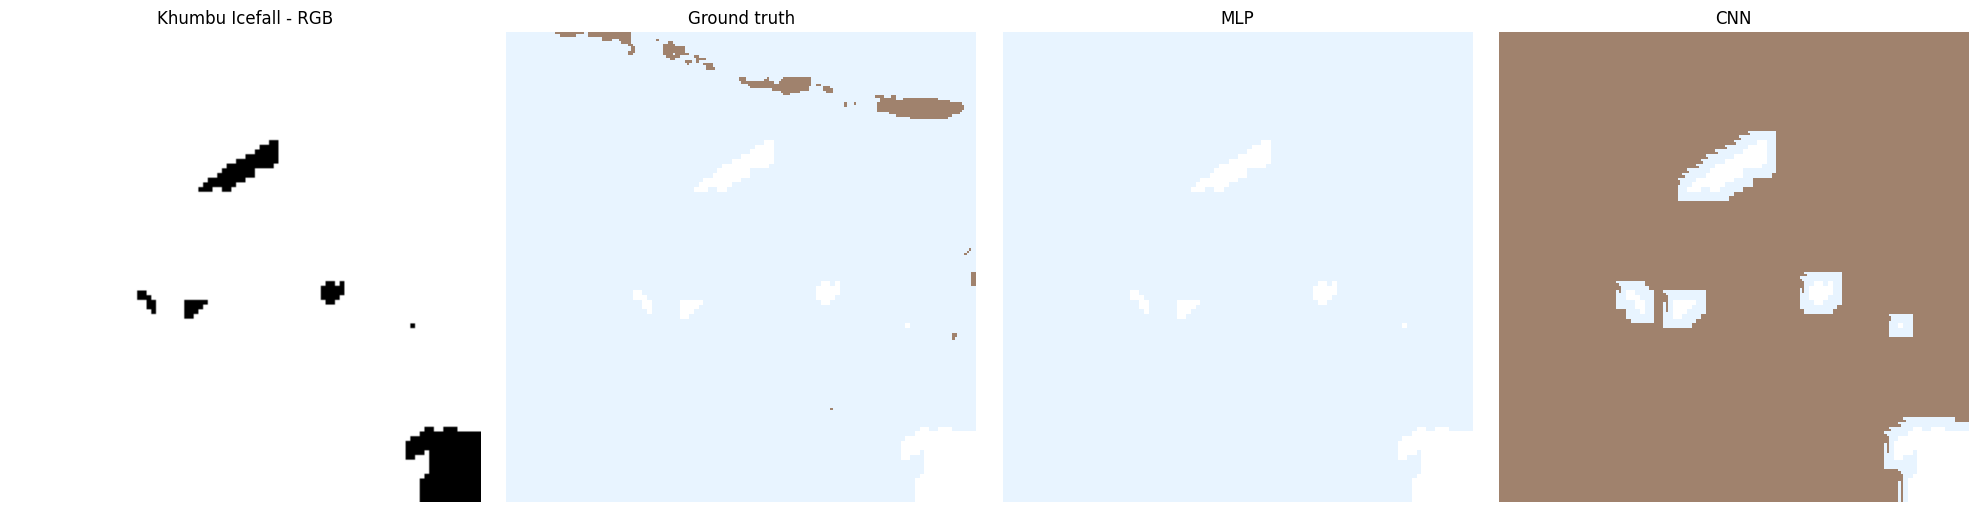

In [16]:
# Zoom on the Khumbu Icefall (only when the scene is georeferenced)
if meta.get("bounds") is not None and meta.get("epsg"):
    import pyproj
    x, yv = pyproj.Transformer.from_crs(4326, meta["epsg"], always_xy=True).transform(*ICEFALL_LONLAT)
    xmin, ymin, xmax, ymax = meta["bounds"]
    cc, rr = int((x - xmin) / RES), int((ymax - yv) / RES)
    h = 100; r0, r1, c0, c1 = max(0, rr-h), min(H, rr+h), max(0, cc-h), min(W, cc+h)
    fig, ax = plt.subplots(1, 4, figsize=(20, 5))
    ax[0].imshow(rgb(img[:, r0:r1, c0:c1])); ax[0].set_title("Khumbu Icefall - RGB")
    for a, l, t in zip(ax[1:], [lab, map_mlp, map_cnn], ["Ground truth", "MLP", "CNN"]):
        show_label(a, np.where(valid, l, -1)[r0:r1, c0:c1], t)
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()
else:
    print("Scene not georeferenced - skipping icefall zoom.")

## 11. Summary and discussion points (for the report later)

- Compare the **MLP** vs **CNN** table in section 9: the CNN gets spatial context from the 9Ã—9 window, the MLP only spectral values.
- Check the **confusion matrices** to see which classes are mixed up (typically Snow/Ice â†” Bare/Rock around debris-covered ice and shadowed slopes).
- Per-class AUC values are usually very high even when F1 is lower, because AUC measures ranking quality and is insensitive to the decision threshold.
- Limitations: labels are a derived product (some label noise), single-season composite, no terrain (DEM / slope) features, class caps change the class prior of the test sample.
- Possible extensions: add Copernicus DEM slope/elevation, a U-Net for dense prediction, multi-temporal inputs.